<a href="https://colab.research.google.com/github/Jorgellamocca/S2S-PER/blob/main/APS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip install -q dynamical-catalog

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 815.6/815.6 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 81.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 66.3 MB/s eta 0:00:00


In [3]:
# ============================================================
# ECMWF IFS ENS - PRONÓSTICO SUBESTACIONAL (46 DÍAS)
# CONSULTA DE VARIABLES DISPONIBLES
# ============================================================

%pip install -q dynamical-catalog

import dynamical_catalog

CATALOGO = "ecmwf-ifs-ens-forecast-46-day-daily-1-5-degree"

print("Abriendo catálogo ECMWF...")

ds = dynamical_catalog.open(
    CATALOGO,
    chunks=None
)

print("\n" + "=" * 85)
print("VARIABLES DISPONIBLES - ECMWF IFS ENS")
print("=" * 85)

for i, variable in enumerate(ds.data_vars, 1):

    da = ds[variable]

    nombre = da.attrs.get("long_name", "")
    unidades = da.attrs.get("units", "")

    print(f"\n{i:02d}. {variable}")
    print(f"    Descripción : {nombre}")
    print(f"    Unidades    : {unidades}")
    print(f"    Dimensiones : {da.dims}")

print("\n" + "=" * 85)
print("TOTAL DE VARIABLES:", len(ds.data_vars))
print("=" * 85)

Abriendo catálogo ECMWF...

VARIABLES DISPONIBLES - ECMWF IFS ENS

01. average_convective_available_potential_energy_surface
    Descripción : Convective available potential energy
    Unidades    : J kg-1
    Dimensiones : ('init_time', 'lead_time', 'ensemble_member', 'latitude', 'longitude')

02. average_dew_point_temperature_2m
    Descripción : Mean 2 metre dewpoint temperature in the last 24 hours
    Unidades    : degree_Celsius
    Dimensiones : ('init_time', 'lead_time', 'ensemble_member', 'latitude', 'longitude')

03. average_temperature_2m
    Descripción : Mean temperature at 2 metres in the last 24 hours
    Unidades    : degree_Celsius
    Dimensiones : ('init_time', 'lead_time', 'ensemble_member', 'latitude', 'longitude')

04. downward_sensible_heat_flux_surface
    Descripción : Time-mean surface sensible heat flux
    Unidades    : W m-2
    Dimensiones : ('init_time', 'lead_time', 'ensemble_member', 'latitude', 'longitude')

05. downward_short_wave_radiation_flux_surfa

ECMWF IFS ENS - ANTICICLÓN DEL PACÍFICO SUR

Inicialización: 2026-10-19 00:00:00
Miembros: 101

Longitud seleccionada: 90.0°O

Calculando promedio del ensamble...
Promedio calculado correctamente.


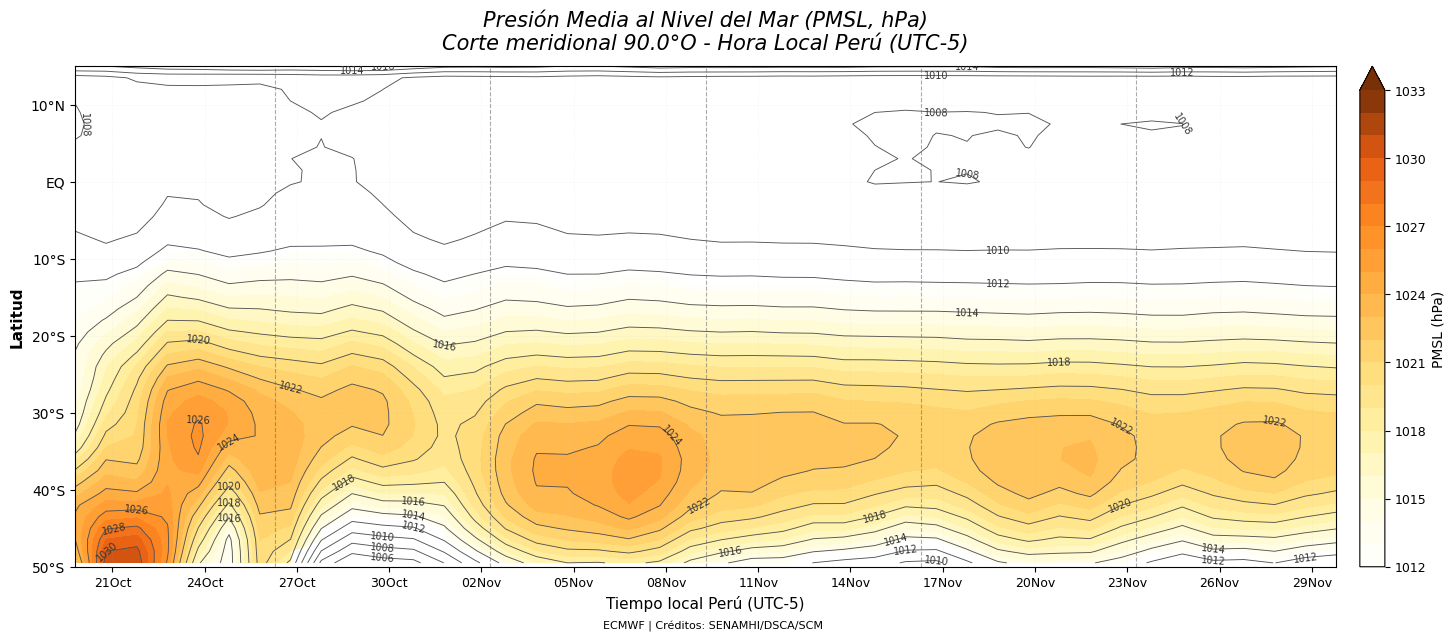


PROCESAMIENTO COMPLETADO
Modelo: ECMWF IFS ENS
Inicialización: 2026-10-19 00:00:00
Miembros: 101
Periodo: 19/10/2026 a 29/11/2026
Longitud: -90.0
Barra de colores: 1012-1033 hPa
Isobaras: cada 2 hPa
Etiquetas: sin fondo ni borde blanco
Archivo PNG: /content/APS_ECMWF_HOVMOLLER/ECMWF_APS_PMSL_HOV_90.0W_20261019.png


In [8]:
# -*- coding: utf-8 -*-
# ================================================================
# ECMWF IFS ENS | ANTICICLÓN DEL PACÍFICO SUR
# HOVMÖLLER DE PRESIÓN MEDIA AL NIVEL DEL MAR
#
# Corte meridional: 90°O
# Pronóstico: 42 días (6 semanas)
# Promedio del ensamble
# Resolución: 1.5°
#
# Barra de colores: 1012 a 1033 hPa
# Isobaras: cada 2 hPa
# Etiquetas SIN fondo ni borde blanco
# Sin interpolación ni suavizado
#
# Créditos: SENAMHI/DSCA/SCM
# ================================================================

# ================================================================
# 0. INSTALACIÓN
# ================================================================

%pip install -q dynamical-catalog netcdf4

# ================================================================
# 1. LIBRERÍAS
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates

import dynamical_catalog

# ================================================================
# 2. CONFIGURACIÓN
# ================================================================

CATALOGO = (
    "ecmwf-ifs-ens-forecast-46-day-daily-1-5-degree"
)

VARIABLE = "pressure_reduced_to_mean_sea_level"

OUTPUT_DIR = "/content/APS_ECMWF_HOVMOLLER"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Corte meridional
LONGITUD_CORTE = -90.0

# Dominio latitudinal
LAT_MIN = -50
LAT_MAX = 15

# Pronóstico
DIA_INICIAL = 1
N_DIAS = 42

# Barra de colores
P_MIN = 1012
P_MAX = 1033

# Isobaras cada 2 hPa
ISOBARAS = np.arange(960, 1060, 2)

# Niveles de sombreado
NIVELES_COLOR = np.arange(
    P_MIN,
    P_MAX + 1,
    1
)

# ================================================================
# 3. ABRIR CATÁLOGO ECMWF
# ================================================================

print("=" * 80)
print("ECMWF IFS ENS - ANTICICLÓN DEL PACÍFICO SUR")
print("=" * 80)

ds = dynamical_catalog.open(
    CATALOGO,
    chunks=None
)

if VARIABLE not in ds.data_vars:
    raise KeyError(
        f"No se encontró la variable: {VARIABLE}"
    )

INIT_TIME = ds.init_time.values[-1]
INIT = pd.Timestamp(INIT_TIME)

N_MIEMBROS = ds.sizes["ensemble_member"]

print("\nInicialización:", INIT)
print("Miembros:", N_MIEMBROS)

# ================================================================
# 4. SELECCIONAR VARIABLE
# ================================================================

p = ds[VARIABLE].sel(
    init_time=INIT_TIME
)

# Convertir longitud de 0-360 a -180/180
if float(p.longitude.max()) > 180:

    p = p.assign_coords(
        longitude=(
            (p.longitude + 180) % 360
        ) - 180
    )

p = p.sortby("longitude")
p = p.sortby("latitude")

# ================================================================
# 5. CORTE MERIDIONAL
# ================================================================

p = p.sel(
    longitude=LONGITUD_CORTE,
    method="nearest"
)

LONGITUD_REAL = float(
    p.longitude.values
)

p = p.sel(
    latitude=slice(LAT_MIN, LAT_MAX)
)

print(
    "\nLongitud seleccionada:",
    f"{abs(LONGITUD_REAL):.1f}°O"
)

# ================================================================
# 6. SELECCIONAR 42 DÍAS
# ================================================================

lead_esperado = pd.timedelta_range(
    start=pd.Timedelta(days=DIA_INICIAL),
    periods=N_DIAS,
    freq="D"
)

lead_disponible = pd.to_timedelta(
    p.lead_time.values
)

faltantes = lead_esperado.difference(
    lead_disponible
)

if len(faltantes) > 0:

    raise ValueError(
        f"Faltan plazos diarios: {faltantes}"
    )

p = p.sel(
    lead_time=lead_esperado
)

# ================================================================
# 7. PROMEDIO DEL ENSAMBLE
# ================================================================

print("\nCalculando promedio del ensamble...")

p_media = (
    p.mean(
        dim="ensemble_member",
        skipna=True
    ) / 100.0
)

p_media = p_media.transpose(
    "latitude",
    "lead_time"
).load()

print("Promedio calculado correctamente.")

# ================================================================
# 8. FECHAS
# ================================================================

fechas_utc = pd.DatetimeIndex(
    INIT + pd.to_timedelta(
        p_media.lead_time.values
    )
)

# Hora local Perú UTC-5
fechas_local = (
    fechas_utc - pd.Timedelta(hours=5)
)

latitudes = p_media.latitude.values
P = p_media.values

# ================================================================
# 9. PALETA DE PRESIÓN 1012-1033 hPa
# ================================================================

COLORES = [
    (1012, "#FFFFFF"),
    (1015, "#FFFDE0"),
    (1018, "#FFF2A6"),
    (1021, "#FFDA75"),
    (1024, "#FFB347"),
    (1027, "#FF8C24"),
    (1030, "#E65C12"),
    (1033, "#783008")
]

CMAP = mcolors.LinearSegmentedColormap.from_list(
    "PMSL_APS",
    [
        (
            (valor - P_MIN) / (P_MAX - P_MIN),
            color
        )
        for valor, color in COLORES
    ],
    N=256
)

CMAP.set_over("#783008")
CMAP.set_under("#FFFFFF")

NORM = mcolors.Normalize(
    vmin=P_MIN,
    vmax=P_MAX
)

# ================================================================
# 10. FIGURA
# ================================================================

fig, ax = plt.subplots(
    figsize=(17, 6.5),
    facecolor="white"
)

# ------------------------------------------------------------
# SOMBREADO DE PRESIÓN
# ------------------------------------------------------------

P_SOMBREADO = np.ma.masked_less(
    P,
    P_MIN
)

cf = ax.contourf(
    fechas_local,
    latitudes,
    P_SOMBREADO,
    levels=NIVELES_COLOR,
    cmap=CMAP,
    norm=NORM,
    extend="max"
)

# ------------------------------------------------------------
# ISOBARAS CADA 2 hPa
# ETIQUETAS SIN FONDO NI BORDE BLANCO
# ------------------------------------------------------------

cs = ax.contour(
    fechas_local,
    latitudes,
    P,
    levels=ISOBARAS,
    colors="#555555",
    linewidths=0.65
)

etiquetas = ax.clabel(
    cs,
    inline=False,
    fontsize=7,
    fmt="%d",
    colors="#333333"
)

# Eliminar cualquier efecto de fondo o contorno
for etiqueta in etiquetas:
    etiqueta.set_path_effects([])
    etiqueta.set_bbox(None)

# ================================================================
# 11. SEPARACIÓN DE LAS 6 SEMANAS
# ================================================================

for semana in range(1, 6):

    indice = semana * 7

    fecha_separacion = (
        fechas_local[indice - 1]
        + (
            fechas_local[indice]
            - fechas_local[indice - 1]
        ) / 2
    )

    ax.axvline(
        fecha_separacion,
        color="#666666",
        linestyle="--",
        linewidth=0.8,
        alpha=0.55
    )

# ================================================================
# 12. EJES
# ================================================================

ax.set_ylim(
    LAT_MIN,
    LAT_MAX
)

ax.set_yticks([
    -50, -40, -30, -20, -10, 0, 10
])

ax.set_yticklabels([
    "50°S",
    "40°S",
    "30°S",
    "20°S",
    "10°S",
    "EQ",
    "10°N"
])

ax.set_ylabel(
    "Latitud",
    fontsize=11,
    fontweight="bold"
)

# Fechas cada 3 días
ax.xaxis.set_major_locator(
    mdates.DayLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d%b")
)

ax.tick_params(
    axis="x",
    labelsize=9
)

ax.tick_params(
    axis="y",
    labelsize=10
)

ax.grid(
    linestyle=":",
    linewidth=0.4,
    alpha=0.25
)

ax.set_xlabel(
    "Tiempo local Perú (UTC-5)",
    fontsize=11
)

# ================================================================
# 13. TÍTULO
# ================================================================

titulo = (
    "Presión Media al Nivel del Mar (PMSL, hPa)\n"
    f"Corte meridional {abs(LONGITUD_REAL):.1f}°O "
    "- Hora Local Perú (UTC-5)"
)

ax.set_title(
    titulo,
    fontsize=15,
    fontstyle="italic",
    pad=12
)

# ================================================================
# 14. BARRA DE COLORES 1012-1033 hPa
# ================================================================

cbar = fig.colorbar(
    cf,
    ax=ax,
    orientation="vertical",
    pad=0.018,
    fraction=0.025,
    ticks=np.arange(1012, 1034, 3)
)

cbar.set_label(
    "PMSL (hPa)",
    fontsize=10
)

cbar.ax.tick_params(
    labelsize=9
)

# ================================================================
# 15. CRÉDITOS
# ================================================================

fig.text(
    0.5,
    0.015,
    "ECMWF | Créditos: SENAMHI/DSCA/SCM",
    ha="center",
    fontsize=8
)

# ================================================================
# 16. GUARDAR PNG
# ================================================================

archivo = os.path.join(
    OUTPUT_DIR,
    (
        f"ECMWF_APS_PMSL_HOV_"
        f"{abs(LONGITUD_REAL):.1f}W_"
        f"{INIT:%Y%m%d}.png"
    )
)

plt.savefig(
    archivo,
    dpi=250,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ================================================================
# 17. RESUMEN
# ================================================================

print("\n" + "=" * 80)
print("PROCESAMIENTO COMPLETADO")
print("=" * 80)

print("Modelo: ECMWF IFS ENS")
print("Inicialización:", INIT)
print("Miembros:", N_MIEMBROS)

print(
    "Periodo:",
    fechas_local[0].strftime("%d/%m/%Y"),
    "a",
    fechas_local[-1].strftime("%d/%m/%Y")
)

print("Longitud:", LONGITUD_REAL)
print("Barra de colores: 1012-1033 hPa")
print("Isobaras: cada 2 hPa")
print("Etiquetas: sin fondo ni borde blanco")
print("Archivo PNG:", archivo)